# 2026-ENC-AI Seminář 05 Studentský Lab Notebook (Google Colab)

> *Následující kód a texty tvoří kompletní podklad určený k přímému vložení do prostředí Google Colab.*


# 🎓 Laboratorní cvičení: Inteligentní agenti v prostředí Vacuum World 3x3

**Předmět:** 2026 ENC AI
**Časová dotace:** 70 minut  
**Prostředí:** Google Colab (Python 3)  
**Cíl cvičení:** Implementovat reaktivního agenta bez paměti (*Simple Reflex Agent*) a agenta s vnitřním stavem (*Model-Based Agent*) v prostředí $3 \times 3$, provést jejich Monte Carlo srovnání a vyhodnotit vliv vnitřního modelu na efektivitu chování.

---

## 1. Teoretický úvod & Rámec PEAS

Podle publikace *Russell & Norvig* definujeme agenta jako entitu, která vnímá prostředí pomocí **senzorů** a působí na něj pomocí **efektorů**.

### Rámec PEAS pro náš Vacuum World 3x3:
* **P (Performance / Míra výkonu):**
  * $+10$ bodů za každé uklizené špinavé políčko.
  * $-1$ bod za každý pohyb (spotřeba energie).
  * $-1$ bod za zbytečné vysávání již čistého políčka.
  * $-5$ bodů za náraz do zdi (pohyb mimo mřížku).
* **E (Environment / Prostředí):** Mřížka $3 \times 3$ (9 políček). Každé políčko je buď `ČISTÉ` (0), nebo `ŠPINAVÉ` (1). Pozice agenta je určena souřadnicemi $(r, c) \in \{0, 1, 2\}^2$.
  * *Velikost stavového prostoru:* $9 \text{ pozic} \times 2^9 \text{ stavů špíny} = 4\,608$ možných stavů.
* **A (Actuators / Efektory):** Akce z množiny `{'UP', 'DOWN', 'LEFT', 'RIGHT', 'CLEAN', 'NOOP'}`.
* **S (Sensors / Senzory):** Lokální vnímání – agent zná pouze svoji aktuální pozici a stav aktuálního políčka: `(r, c, is_dirty)`. Nevidí stav ostatních políček.

> ⚠️ **Důležité upozornění k indexování matice:**
> Mřížka je reprezentována maticí NumPy s indexy `[řádek, sloupec]`.
> * `r = 0` je **horní** řádek, `r = 2` je **dolní** řádek.
> * Pohyb `UP` znamená zmenšení indexu řádku (`r - 1`). Pohyb `DOWN` znamená zvětšení (`r + 1`).

---

### Buňka 1: Simulátor prostředí (Spusťte buňku)

In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import clear_output
import time

class VacuumEnvironment3x3:
    """Prostředí mřížky 3x3 pro vysavač."""
    def __init__(self, dirt_probability=0.5):
        self.grid_size = 3
        # 0 = čisté, 1 = špinavé
        self.grid = np.random.choice([0, 1], size=(3, 3), p=[1-dirt_probability, dirt_probability])
        self.agent_pos = [random.randint(0, 2), random.randint(0, 2)]
        self.performance_score = 0
        self.steps = 0

    def get_percept(self):
        """Vrací lokální percept agenta: (r, c, is_dirty)"""
        r, c = self.agent_pos
        is_dirty = bool(self.grid[r, c] == 1)
        return (r, c, is_dirty)

    def step(self, action):
        """Provede akci agenta, upraví skóre a vrátí nový percept a skóre."""
        self.steps += 1
        r, c = self.agent_pos

        if action == 'CLEAN':
            if self.grid[r, c] == 1:
                self.grid[r, c] = 0
                self.performance_score += 10  # Odměna za úklid
            else:
                self.performance_score -= 1   # Zbytečné vysávání

        elif action in ['UP', 'DOWN', 'LEFT', 'RIGHT']:
            self.performance_score -= 1       # Náklady na pohyb
            new_r, new_c = r, c
            if action == 'UP': new_r -= 1
            elif action == 'DOWN': new_r += 1
            elif action == 'LEFT': new_c -= 1
            elif action == 'RIGHT': new_c += 1

            # Kontrola hranic mřížky
            if 0 <= new_r < 3 and 0 <= new_c < 3:
                self.agent_pos = [new_r, new_c]
            else:
                self.performance_score -= 5   # Penalizace za náraz do zdi

        elif action == 'NOOP':
            pass

        return self.get_percept(), self.performance_score

    def is_completely_clean(self):
        return np.sum(self.grid) == 0

print("✅ Simulátor prostředí úspěšně načten.")

✅ Simulátor prostředí úspěšně načten.


---

### Buňka 2: Úkol 1 – Simple Reflex Agent (Doplňte kód)

In [2]:
class SimpleReflexAgent:
    """
    Jednoduchý reflexní agent bez paměti.
    Reaguje výhradně na aktuální percept (pozice a zda je políčko špinavé).
    """
    def __init__(self):
        self.actions = ['UP', 'DOWN', 'LEFT', 'RIGHT']

    def select_action(self, percept):
        r, c, is_dirty = percept

        # =========================================================================
        # ÚKOL 1: DOPLŇTE LOGIKU REFLEXNÍHO AGENTA
        # 1. Pokud je aktuální políčko špinavé (is_dirty == True), vraťte 'CLEAN'.
        # 2. Pokud je čisté, vyberte náhodnou pohybovou akci z self.actions.
        # =========================================================================
        # --- ZDE DOPLŇTE VÁŠ KÓD ---
        if is_dirty:
            return 'CLEAN'
        else:
            return random.choice(self.actions)
        # =========================================================================

# --- Testovací kontrola pro Úkol 1 ---
test_agent = SimpleReflexAgent()
assert test_agent.select_action((0, 0, True)) == 'CLEAN', "Chyba: Agent měl vysávat špinavé políčko!"
assert test_agent.select_action((0, 0, False)) in ['UP', 'DOWN', 'LEFT', 'RIGHT'], "Chyba: Agent měl zvolit náhodný pohyb!"
print("✅ Test Úkolu 1 proběhl úspěšně.")

✅ Test Úkolu 1 proběhl úspěšně.


---

### Buňka 3: Úkol 2 – Model-Based Agent s pamětí (Doplňte kód)

In [3]:
class ModelBasedAgent:
    """
    Agent s vnitřním stavem (sekvenční pamětí).
    Udržuje si stav navštívených políček a provádí systematický patrolovací průchod mřížkou.
    """
    def __init__(self):
        # Vnitřní model světa (0 = čisté, None = neznámo)
        self.memory_grid = np.full((3, 3), None)
        # Pevně stanovená patrolovací trasa (hadovitý průchod mřížkou 3x3)
        self.patrol_path = [
            (0,0), (0,1), (0,2),
            (1,2), (1,1), (1,0),
            (2,0), (2,1), (2,2)
        ]
        self.target_index = 0

    def select_action(self, percept):
        r, c, is_dirty = percept
        self.memory_grid[r, c] = 0  # Aktualizace vnitřní paměti navštívených polí

        # =========================================================================
        # ÚKOL 2: DOPLŇTE LOGIKU MODELOVÉHO AGENTA
        # 1. Pokud je políčko špinavé, vraťte 'CLEAN' (neinkrementujte target_index!).
        # 2. Pokud je políčko čisté a dosáhli jsme cíle (r, c) == self.patrol_path[self.target_index]:
        #    - Posuňte target_index na další políčko v sekvenci patrol_path (s využitím modulo len(self.patrol_path)).
        # 3. Určete směrovou akci ('UP', 'DOWN', 'LEFT', 'RIGHT') směřující k aktuálnímu cíli self.patrol_path[self.target_index].
        # =========================================================================
        # --- ZDE DOPLŇTE VÁŠ KÓD ---
        if is_dirty:
            return 'CLEAN'

        if (r, c) == self.patrol_path[self.target_index]:
            self.target_index = (self.target_index + 1) % len(self.patrol_path)

        target_r, target_c = self.patrol_path[self.target_index]

        if target_r < r: return 'UP'
        if target_r > r: return 'DOWN'
        if target_c < c: return 'LEFT'
        if target_c > c: return 'RIGHT'

        return 'NOOP'
        # =========================================================================

# --- Testovací kontrola pro Úkol 2 ---
mb_agent = ModelBasedAgent()
assert mb_agent.select_action((0, 0, True)) == 'CLEAN', "Chyba: Agent měl při špíně upřednostnit CLEAN!"
assert mb_agent.select_action((0, 0, False)) == 'RIGHT', "Chyba: Z pozice (0,0) měl agent vyrazit doprava k (0,1)!"
print("✅ Test Úkolu 2 proběhl úspěšně.")

✅ Test Úkolu 2 proběhl úspěšně.


---

### Buňka 4: Náhodný agent pro srovnání (Spusťte buňku)

In [4]:
class RandomAgent:
    """Zcela náhodný agent bez pravidel pro porovnání výkonu."""
    def __init__(self):
        self.actions = ['UP', 'DOWN', 'LEFT', 'RIGHT', 'CLEAN']

    def select_action(self, percept):
        return random.choice(self.actions)

print("✅ RandomAgent načten.")

✅ RandomAgent načten.


---

### Buňka 5: Grafická vizualizace úklidu v Colabu

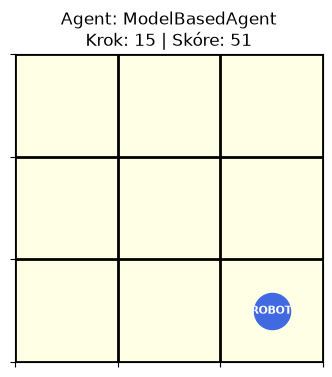

✨ Mřížka je zcela čistá!


In [5]:
def run_visual_demo(agent_cls, steps=25, delay=0.3):
    """Spustí grafickou animaci jednoho úklidového cyklu."""
    env = VacuumEnvironment3x3(dirt_probability=0.5)
    agent = agent_cls()

    for step_num in range(steps):
        clear_output(wait=True)
        fig, ax = plt.subplots(figsize=(4, 4))

        # Zobrazení mřížky (0 = bílá/čisto, 1 = hnědá/špína)
        grid_data = np.copy(env.grid)
        ax.imshow(grid_data, cmap='YlOrBr', vmin=0, vmax=1.5)

        # Vykreslení pozice agenta
        r, c = env.agent_pos
        ax.plot(c, r, marker='o', markersize=26, color='royalblue')
        ax.text(c, r, 'ROBOT', color='white', ha='center', va='center', fontsize=8, fontweight='bold')

        ax.set_xticks(np.arange(-0.5, 3, 1))
        ax.set_yticks(np.arange(-0.5, 3, 1))
        ax.grid(color='black', linestyle='-', linewidth=2)
        ax.set_xticklabels([])
        ax.set_yticklabels([])

        plt.title(f"Agent: {agent_cls.__name__}\nKrok: {env.steps} | Skóre: {env.performance_score}")
        plt.show()

        if env.is_completely_clean():
            print("✨ Mřížka je zcela čistá!")
            break

        percept = env.get_percept()
        action = agent.select_action(percept)
        env.step(action)
        time.sleep(delay)

# Spusťte vizualizaci pro ModelBasedAgent
run_visual_demo(ModelBasedAgent)

---

### Buňka 6: Úkol 3 – Monte Carlo Benchmark a porovnání agentů

In [6]:
def run_simulation(agent_cls, steps=50, runs=100):
    """Spustí rozsáhlou simulaci na 100 náhodných prostředí."""
    total_scores = []
    cleaned_ratios = []

    for _ in range(runs):
        env = VacuumEnvironment3x3(dirt_probability=0.5)
        agent = agent_cls()
        initial_dirt = np.sum(env.grid)

        for _ in range(steps):
            percept = env.get_percept()
            action = agent.select_action(percept)
            env.step(action)
            if env.is_completely_clean():
                break

        total_scores.append(env.performance_score)
        dirt_left = np.sum(env.grid)
        cleaned_ratio = 1.0 if initial_dirt == 0 else (initial_dirt - dirt_left) / initial_dirt
        cleaned_ratios.append(cleaned_ratio)

    return np.mean(total_scores), np.mean(cleaned_ratios)

# Spuštění srovnání pro všechny 3 typy agentů
agents = [RandomAgent, SimpleReflexAgent, ModelBasedAgent]

print("=" * 60)
print("SROVNÁVACÍ BENCHMARK AGENTŮ (Průměr z 100 běhů po 50 krocích)")
print("=" * 60)

for agent_cls in agents:
    mean_score, mean_clean = run_simulation(agent_cls)
    print(f"{agent_cls.__name__:<20} | Průměrné skóre: {mean_score:6.2f} | Uklizeno: {mean_clean*100:5.1f}%")
print("=" * 60)

SROVNÁVACÍ BENCHMARK AGENTŮ (Průměr z 100 běhů po 50 krocích)
RandomAgent          | Průměrné skóre: -84.53 | Uklizeno:  56.9%
SimpleReflexAgent    | Průměrné skóre: -37.14 | Uklizeno:  95.2%
ModelBasedAgent      | Průměrné skóre:  36.76 | Uklizeno: 100.0%


## Výzva A
Dynamické prostředí se spavnováním špíny
Přidejte do simulátoru možnost, že v každém kroku vznikne na náhodně zvoleném čistém políčku nová špína s pravděpodobností  𝑝𝑠𝑝𝑎𝑤𝑛=0.05

In [7]:
# Do metody step() třídy VacuumEnvironment3x3 - vložte váš kód:

# Výzva A: Dynamické prostředí – v každém kroku může vzniknout nová špína (p_spawn = 0.05)

class DynamicVacuumEnvironment3x3(VacuumEnvironment3x3):
    """Prostředí 3x3, kde po každém kroku může na náhodném čistém políčku vzniknout špína."""
    def __init__(self, dirt_probability=0.5, spawn_probability=0.05):
        super().__init__(dirt_probability)
        self.spawn_probability = spawn_probability
        self.cleaned_count = 0   # kolik špíny agent celkem uklidil
        self.spawned_count = 0   # kolik špíny nově vzniklo

    def step(self, action):
        r, c = self.agent_pos
        if action == 'CLEAN' and self.grid[r, c] == 1:
            self.cleaned_count += 1

        # Původní logika kroku (pohyb, úklid, skóre)
        super().step(action)

        # Spawn nové špíny na náhodném čistém políčku
        if random.random() < self.spawn_probability:
            clean_cells = list(zip(*np.where(self.grid == 0)))
            if clean_cells:
                sr, sc = random.choice(clean_cells)
                self.grid[sr, sc] = 1
                self.spawned_count += 1

        return self.get_percept(), self.performance_score


def run_dynamic_simulation(agent_cls, steps=50, runs=100, spawn_probability=0.05):
    """Simulace v dynamickém prostředí. Neukončuje se při čisté mřížce, protože špína se může vrátit."""
    scores, dirt_left, cleaned, spawned = [], [], [], []

    for _ in range(runs):
        env = DynamicVacuumEnvironment3x3(dirt_probability=0.5, spawn_probability=spawn_probability)
        agent = agent_cls()

        for _ in range(steps):
            percept = env.get_percept()
            action = agent.select_action(percept)
            env.step(action)

        scores.append(env.performance_score)
        dirt_left.append(np.sum(env.grid))
        cleaned.append(env.cleaned_count)
        spawned.append(env.spawned_count)

    return np.mean(scores), np.mean(dirt_left), np.mean(cleaned), np.mean(spawned)


print("=" * 85)
print("DYNAMICKÉ PROSTŘEDÍ (p_spawn = 0.05, průměr ze 100 běhů po 50 krocích)")
print("=" * 85)
for agent_cls in [RandomAgent, SimpleReflexAgent, ModelBasedAgent]:
    s, d, cl, sp = run_dynamic_simulation(agent_cls)
    print(f"{agent_cls.__name__:<20} | Skóre: {s:7.2f} | Uklizeno: {cl:4.2f} | "
          f"Nově vzniklo: {sp:4.2f} | Zbylá špína na konci: {d:4.2f}")
print("=" * 85)



DYNAMICKÉ PROSTŘEDÍ (p_spawn = 0.05, průměr ze 100 běhů po 50 krocích)
RandomAgent          | Skóre:  -82.09 | Uklizeno: 3.26 | Nově vzniklo: 2.46 | Zbylá špína na konci: 3.69
SimpleReflexAgent    | Skóre:  -61.60 | Uklizeno: 5.70 | Nově vzniklo: 2.33 | Zbylá špína na konci: 1.14
ModelBasedAgent      | Skóre:   21.83 | Uklizeno: 6.53 | Nově vzniklo: 2.42 | Zbylá špína na konci: 0.32


*Úkol:* Otestujte, jak se změní efektivita `ModelBasedAgent` se statickou trasou oproti agentovi, který si udržuje mapu a neustále patroluje.


**Výsledky (dynamické prostředí, p_spawn = 0.05, 100 běhů × 50 kroků):**

| Agent | Skóre (statické) | Skóre (dynamické) | Zbylá špína na konci |
|---|---|---|---|
| RandomAgent | -84.53 | -82.09 | 3.69 |
| SimpleReflexAgent | -37.14 | -61.60 | 1.14 |
| ModelBasedAgent | 36.76 | 21.83 | 0.32 |

**Závěr:** 

`ModelBasedAgent` zůstává i v dynamickém prostředí nejefektivnější. Díky neustálé cyklické patrole (modulo přes trasu) se k nově vzniklé špíně vždy znovu dostane a na konci simulace zbývá v průměru jen 0.32 špinavého políčka. Jeho skóre ale kleslo (36.76 → 21.83), protože simulace už nekončí při čisté mřížce a agent musí doběhnout pohyb všech 50 kroků. 

Nevýhodou statické trasy je, že nově vzniklá špína za agentem musí čekat, až ji trasa znovu projde, a jeho paměť (`memory_grid`) si políčka pamatuje jako čistá navždy, i když se mohla znovu zašpinit.


---
## 📝 Závěrečný protokol (Vyplňte a odevzdejte)

**Jméno a příjmení:**

**Studijní skupina:**

### 1. Záznam Naměřených Výsledků
Doplňte naměřené hodnoty z Vaší simulace (Buňka 6):
* **RandomAgent:** Průměrné skóre = `___-84.53____` | Úklid = `_56.9______ %`
* **SimpleReflexAgent:** Průměrné skóre = `__-37.14_____` | Úklid = `_____95.2__ %`
* **ModelBasedAgent:** Průměrné skóre = `____36.76___` | Úklid = `___100____ %`

---

### 2. Analytické Otázky

**Otázka A:** Proč dosahuje `SimpleReflexAgent` podstatně nižšího skóre než `ModelBasedAgent`, přestože oba reagují na špínu na aktuálním políčku okamžitě?

**SimpleReflexAgent nemá žádnout paměť. Reaguje přímo na daný vjem (v našem případě na políčko). V případě, že je políčko čistě zvolí náhodný směr takže opakovaně chodí již po uklizených částech. ModelBasedAgent si udržuje svoje vnitří stavy a prochází systematicky**

---

**Otázka B:** Jak by se změnila efektivita `ModelBasedAgent`, pokud by prostředí bylo **dynamické** (tj. špína by během úklidu náhodně vznikala na již uklizených políčkách)? Jakou změnu vnitřního modelu by tato situace vyžadovala?

**Ačkoliv agent v dynamickém prostředí ztrácí část své efektivity, díky svému cyklickému pohybu zůstává nejlepším, avšak pro další zlepšení by si musel pamatovat čas poslední návštěvy každého místa a nepřetržitě prostor patrolovat, místo aby naivně předpokládal, že jednou vyčištěné políčko zůstane čisté navždy.**

---

**Otázka C:** Jaká je velikost stavového prostoru u mřížky $4 \times 4$ při zachování stejných pravidel (2 stavy špíny pro každé políčko)? Uveďte přesný výpočet.

**Stav = pozice agenta × stav špíny všech políček.
Mřížka 4×4 má 16 políček → 16 možných pozic agenta.
Každé políčko má 2 stavy (čisté/špinavé) → 2^16 = 65 536 kombinací špíny.
Velikost stavového prostoru = 16 × 2^16 = 16 × 65 536 = 1 048 576 stavů.**

---
**Krátká reflexe na cvičení - díky za pomoc!**

- Který úkol nebo koncept pro vás byl dnes nejjednodušší?
**Nejjednodušší byl Úkol 1 Simple Reflex Agent, protože jeho logika je jen jedna podmínka a stačilo to spustit.**
- Po zodpovězení všech otázek v návaznosti na kód, vnímate že chápete jak funguje `Simple Reflex Agent`, k čemu se hodí a jakéí jsou jeho omezení v porovnání k `Model-Based Agent`?
**Ano. Simple Reflex Agent rozhoduje jen podle aktuálního vjemu, bez paměti (příklad termostat a teplota). Hodí se do jednoduchých a plně pozorovatelných prostředí, kde správná akce závisí jen na tom, co agent právě vidí. Jeho omezení je, že neví, kde už byl, takže bloudí, opakuje kroky a naráží na chyby. Model-Based Agent si udržuje vnitřní stav, díky kterému může jednat systematicky a efektivně i v prostředí, které vidí jen částečně.**
